# DeepNT+ experiments

Trains and evaluates the hybrid model on the dataset produced by `Dataset_Build.ipynb`, next to the baselines the
spec requires, with ablations, calibration and simulated active measurement scheduling.

**What DeepNT+ is here**

| Part | Implementation |
|---|---|
| Split-weight spatial GNN | `h' = ReLU(LN(W_s h + W_n mean_N h))`, structural node features plus a summary of the context measurements |
| Tomography layer | GNN predicts a non-negative delay per edge, path RTT `= A x + b` |
| Convex fusion | ridge tomography `min ||A x - y||^2 + a ||x - x0||^2` on the context paths (closed form), fused with the GNN path estimate by a learned per-path gate |
| Temporal branch | TGN node memory (GRU), then GRU + Transformer over the recent measurement history, strictly causal |
| Uncertainty | heteroscedastic Gaussian head, MC-dropout for epistemic variance |
| Active learning | variance and BALD acquisition, simulated by revealing real held-back measurements |

**Protocol.** Graph-level split (train 1-10, validation 11-12, test 13-15). At validation and test the model sees the RTT of the
*observed* paths only and predicts the *hidden* ones. RTT outliers are excluded everywhere. Packet loss has no labels in this
dataset, so no loss head is trained. Normalisation comes from the train graphs only.


In [1]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    THESIS = Path("/content/drive/My Drive/Thesis")
else:
    THESIS = Path(r"C:\Users\KINGDOM\Desktop\Thesis")
PROJECT_ROOT = THESIS / "DeepNT_Output"
PROCESSED = PROJECT_ROOT / "data" / "processed"

# the deepnt_plus package folder: in Colab copy it to  DeepNT_Output/code/deepnt_plus
candidates = [PROJECT_ROOT / "code", THESIS / "colab", Path.cwd(), Path.cwd().parent]
pkg_root = next((c for c in candidates if (c / "deepnt_plus" / "__init__.py").exists()), None)
if pkg_root is None:
    raise FileNotFoundError("deepnt_plus package not found. Copy the folder 'deepnt_plus' to "
                            f"{PROJECT_ROOT / 'code'} (searched: {[str(c) for c in candidates]})")
sys.path.insert(0, str(pkg_root))
REQUIRED_FILES = ["paths_all.csv", "path_ground_truth.csv", "node_features.csv", "edge_features.csv",
                  "tomography/A_graph_01.npz"]


def find_missing():
    return [f for f in REQUIRED_FILES if not (PROCESSED / f).exists()]


missing = find_missing()
if missing and IN_COLAB:
    # files added to Drive from outside this session (browser upload) are invisible to a stale mount
    print("files not visible, refreshing the Drive mount ...")
    drive.mount('/content/drive', force_remount=True)
    missing = find_missing()
if missing:
    seen = sorted(p.name for p in PROCESSED.parent.iterdir()) if PROCESSED.parent.exists() else "(folder does not exist)"
    seen_proc = sorted(p.name for p in PROCESSED.iterdir()) if PROCESSED.exists() else "(folder does not exist)"
    raise FileNotFoundError(f"missing in {PROCESSED}: {missing}\n"
                            f"this session sees data/: {seen}\nthis session sees data/processed/: {seen_proc}\n"
                            "If the files are in Drive but not listed here: Runtime > Disconnect and delete runtime, rerun, "
                            "and check the browser and Colab use the same Google account. Otherwise run Dataset_Build.ipynb.")
print("package:", pkg_root / "deepnt_plus", "\ndata   :", PROCESSED)


package: C:\Users\KINGDOM\Desktop\Thesis\colab\deepnt_plus 
data   : C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed


In [2]:
import pandas as pd
import torch
from deepnt_plus import active, report
from deepnt_plus.data import describe, load_dataset
from deepnt_plus.run import ABLATIONS, VARIANTS, run_all, summarise
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
SEEDS = (0, 1, 2, 3, 4)          # small data: report mean +- std over seeds
EPOCHS = 40  # 40 epochs optimal with CosineAnnealingLR + patience 15
RUN_ABLATIONS = True
RUN_ACTIVE_LEARNING = True
FAST = False               # True = smaller model, for a quick smoke test
RUN_NAME = "run_03"      # run_01 = initial run, run_02 = 15-graph run, run_03 = updated 5 compressed graphs
OUT_DIR = PROJECT_ROOT / "experiments" / "deepnt" / RUN_NAME
graphs, norm = load_dataset(PROCESSED)
overview = describe(graphs)
print(overview.to_string(index=False))
n_tr = overview[overview.split == "train"]
print(f"\ntrain graphs: {int(n_tr.paths.sum())} paths ({int(n_tr.observed.sum())} observed) | "
      f"val hidden paths: {int(overview[overview.split == 'val'].hidden.sum())} | "
      f"test hidden paths: {int(overview[overview.split == 'test'].hidden.sum())}")
print(f"PyTorch {torch.__version__} | packet-loss labels present: "
      f"{bool(any((~torch.isnan(g.loss)).any() for g in graphs.values()))}")


   graph split  nodes  edges  paths  observed  hidden  outliers  median_rtt_ms
graph_01 train   1297   1343    266       120     146         1     177.552994
graph_02 train   1096   1140    265       119     146         0     152.473999
graph_03 train   1280   1310    265       119     146         1     168.434006
graph_04   val   1372   1404    265       119     146         1     208.138000
graph_05  test   1311   1333    265       119     146         0     147.287003

train graphs: 796 paths (358 observed) | val hidden paths: 146 | test hidden paths: 146
PyTorch 2.14.0+cpu | packet-loss labels present: False


In [3]:
gt = pd.read_csv(PROCESSED / "path_ground_truth.csv")
flagged = gt[gt["quality_flag"].astype(str).str.contains("rtt_outlier")]
print(f"{len(flagged)} of {len(gt)} paths are flagged as RTT outliers and left out of context, training and metrics "
      f"(rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:")
print(flagged[["path_id", "graph_id", "split", "rtt_ms", "quality_flag"]].round(1).to_string(index=False) if len(flagged) else "none")
print("\nmonitors per split:")
paths_all = pd.read_csv(PROCESSED / "paths_all.csv")
print(paths_all.groupby(["split", "monitor_id"]).size().unstack(fill_value=0).to_string())


3 of 1326 paths are flagged as RTT outliers and left out of context, training and metrics (rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:
        path_id graph_id split  rtt_ms                      quality_flag
graph_01_p00002 graph_01 train  3601.9 rtt_outlier_high;rtt_outlier_high
graph_03_p00218 graph_03 train  2636.4 rtt_outlier_high;rtt_outlier_high
graph_04_p00185 graph_04   val  1267.8 rtt_outlier_high;rtt_outlier_high

monitors per split:
monitor_id  abz2-uk  acc-gh  dac-bd
split                              
test             75      64     126
train           267     265     264
val              89      88      88


## Train and evaluate everything

Baselines (median, hop-count, LR, RF, MLP, classical convex tomography), GraphSAGE, GAT, DeepNT (static), DeepNT+ (full) and the
ablations, over several seeds. Writes `predictions.csv`, `metrics_summary.csv`, `history.csv`, `config.json` and the checkpoints
to `experiments/deepnt/<run>/`.

In [4]:
pred, summary = run_all(PROCESSED, OUT_DIR, seeds=SEEDS, epochs=EPOCHS, ablations=RUN_ABLATIONS,
                        active_learning=RUN_ACTIVE_LEARNING, fast=FAST)
print("saved to", OUT_DIR)


5 graphs | packet-loss labels available: False
--- GraphSAGE | seed 0
epoch   1 | train loss 0.7582 | val MAE 90.10 ms
epoch  10 | train loss 0.5551 | val MAE 67.72 ms
epoch  20 | train loss 0.4974 | val MAE 67.15 ms
--- GraphSAGE | seed 1
epoch   1 | train loss 0.7548 | val MAE 90.48 ms
epoch  10 | train loss 0.5965 | val MAE 68.49 ms
epoch  20 | train loss 0.4735 | val MAE 60.72 ms
epoch  30 | train loss 0.4324 | val MAE 59.97 ms
epoch  40 | train loss 0.4317 | val MAE 58.87 ms
--- GraphSAGE | seed 2
epoch   1 | train loss 0.7674 | val MAE 90.15 ms
epoch  10 | train loss 0.5289 | val MAE 73.07 ms
epoch  20 | train loss 0.4917 | val MAE 75.12 ms
--- GraphSAGE | seed 3
epoch   1 | train loss 0.7703 | val MAE 90.69 ms
epoch  10 | train loss 0.5477 | val MAE 67.18 ms
epoch  20 | train loss 0.4967 | val MAE 62.94 ms
epoch  30 | train loss 0.4794 | val MAE 63.26 ms
epoch  40 | train loss 0.4413 | val MAE 63.40 ms
--- GraphSAGE | seed 4
epoch   1 | train loss 0.7434 | val MAE 89.94 ms
epoch

## Results on the hidden paths

Test graphs are scored once; validation graphs chose each checkpoint. `MAE`, `RMSE`, `MedAE` are in ms.

In [5]:
cols = ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean", "RMSE_mean", "R2_mean", "n_mean"]
cols = [c for c in cols if c in summary.columns]
for split in ("test", "val"):
    print(f"=== {split} graphs ===")
    print(summary[summary.split == split][cols].sort_values("MAE_mean").round(3).to_string(index=False))


=== test graphs ===
                           model  MAE_mean  MAE_std  MedAE_mean  MdAPE_mean  MAE_log_mean  RMSE_mean  R2_mean  n_mean
                 DeepNT (static)    43.516    1.025      31.073      28.582         0.361     58.271    0.612   146.0
   Convex tomography (classical)    46.279      NaN      36.147      29.160         0.398     58.718    0.606   146.0
                  DeepNT+ (full)    57.492    1.718      47.094      36.973         0.490     73.939    0.375   146.0
DeepNT+ - uncertainty (MSE only)    57.812    1.826      47.692      36.314         0.499     74.050    0.373   146.0
         DeepNT+ - convex fusion    58.765    2.413      51.980      33.512         0.502     71.543    0.415   146.0
         DeepNT (static, causal)    59.021    1.016      46.840      36.543         0.506     76.320    0.335   146.0
       DeepNT+ - temporal branch    59.023    1.002      46.884      36.507         0.506     76.313    0.335   146.0
                             GAT    

## Does each component earn its place?

Ablations remove one part of DeepNT+ (full). `delta_MAE` is the change against the full model, so a positive value means the part helps.
Read it next to `MAE_std`: with this little data, differences smaller than the seed-to-seed spread are not evidence.

In [6]:
test = summary[summary.split == "test"].set_index("model")
full = "DeepNT+ (full)"
if full in test.index:
    names = [n for n in list(ABLATIONS) + ["DeepNT (static, causal)", "DeepNT (static)", "GraphSAGE", "GAT"] if n in test.index]
    table = test.loc[names, ["MAE_mean", "MAE_std"]].copy()
    table["delta_MAE_vs_full"] = table["MAE_mean"] - test.loc[full, "MAE_mean"]
    table["larger_than_seed_spread"] = table["delta_MAE_vs_full"].abs() > (table["MAE_std"].fillna(0) + test.loc[full, "MAE_std"])
    print(f"{full}: MAE {test.loc[full, 'MAE_mean']:.3f} +- {test.loc[full, 'MAE_std']:.3f} ms\n")
    print(table.round(3).to_string())


DeepNT+ (full): MAE 57.492 +- 1.718 ms

                                  MAE_mean  MAE_std  delta_MAE_vs_full  larger_than_seed_spread
model                                                                                          
DeepNT+ - temporal branch           59.023    1.002              1.532                    False
DeepNT+ - convex fusion             58.765    2.413              1.273                    False
DeepNT+ - tomography layer          80.026    2.869             22.534                     True
DeepNT+ - uncertainty (MSE only)    57.812    1.826              0.320                    False
DeepNT+ - context features          63.445    0.897              5.953                     True
DeepNT (static, causal)             59.021    1.016              1.529                    False
DeepNT (static)                     43.516    1.025            -13.976                     True
GraphSAGE                           66.743    8.816              9.252                    False


## Uncertainty calibration

`coverage_90` is the share of hidden paths whose true RTT falls inside the 90% predictive interval (ideal 0.90). `ECE_reg` is the mean
gap between nominal and empirical coverage over 50/80/90/95% (0 is perfect). `NLL` is in log-RTT space.

In [7]:
cal_cols = [c for c in ["model", "NLL_mean", "sharpness_log_mean", "coverage_50_mean", "coverage_80_mean",
                        "coverage_90_mean", "coverage_95_mean", "ECE_reg_mean"] if c in summary.columns]
print(summary[(summary.split == "test") & summary["ECE_reg_mean"].notna()][cal_cols].sort_values("ECE_reg_mean").round(3).to_string(index=False))


                           model  NLL_mean  sharpness_log_mean  coverage_50_mean  coverage_80_mean  coverage_90_mean  coverage_95_mean  ECE_reg_mean
                 DeepNT (static)     0.678               0.362             0.422             0.689             0.797             0.890         0.088
       DeepNT+ - temporal branch     1.553               0.392             0.416             0.595             0.696             0.764         0.170
         DeepNT (static, causal)     1.555               0.392             0.416             0.593             0.696             0.764         0.170
         DeepNT+ - convex fusion     1.458               0.385             0.403             0.615             0.688             0.726         0.180
                  DeepNT+ (full)     1.595               0.366             0.393             0.579             0.693             0.764         0.180
      DeepNT+ - context features     2.350               0.365             0.400             0.545        

## Active measurement scheduling (simulated)

On each test graph a quarter of the hidden paths is held out for scoring. Every round the strategy picks paths from the rest, their
real stored RTT is revealed to the model, and MAE is re-measured on the held-out paths. Lower curves mean better use of the probe budget.

In [8]:
ac_file = OUT_DIR / "active_learning.csv"
if ac_file.exists():
    curves = pd.read_csv(ac_file)
    mean_curve, auc = active.summarise(curves)
    print(auc.round(3).to_string(index=False))
    print("\n(mean MAE over rounds; 'random' is the reference every scheduler must beat)")
else:
    print("active learning was not run")


     strategy  mean_MAE_over_rounds
edge_coverage                35.241
         bald                36.055
 longest_path                36.290
     variance                37.544
       random                38.920

(mean MAE over rounds; 'random' is the reference every scheduler must beat)


## Figures

loss_curve.png


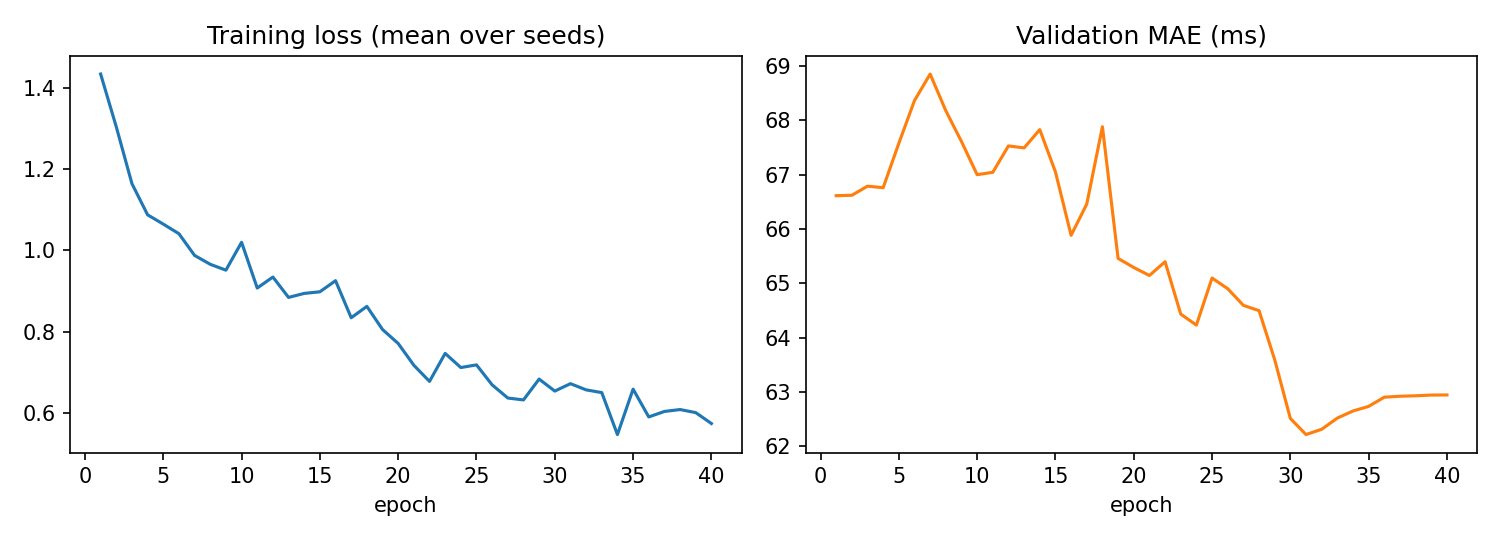

delay_prediction.png


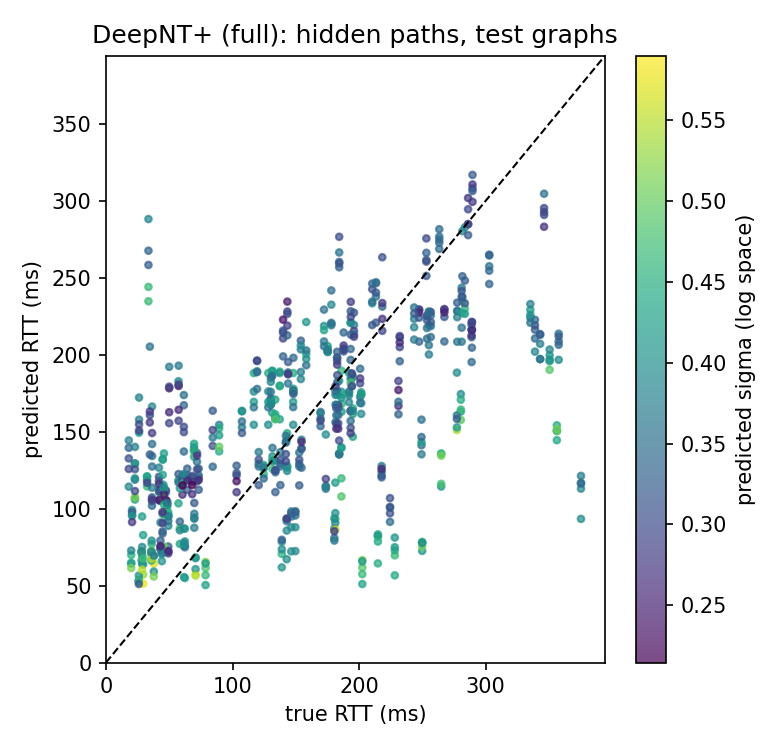

calibration.png


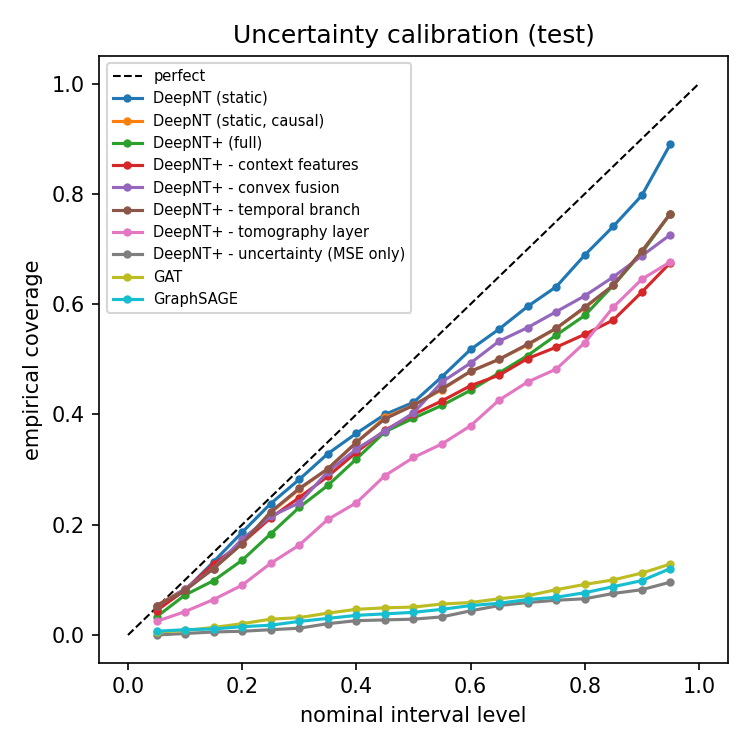

model_comparison.png


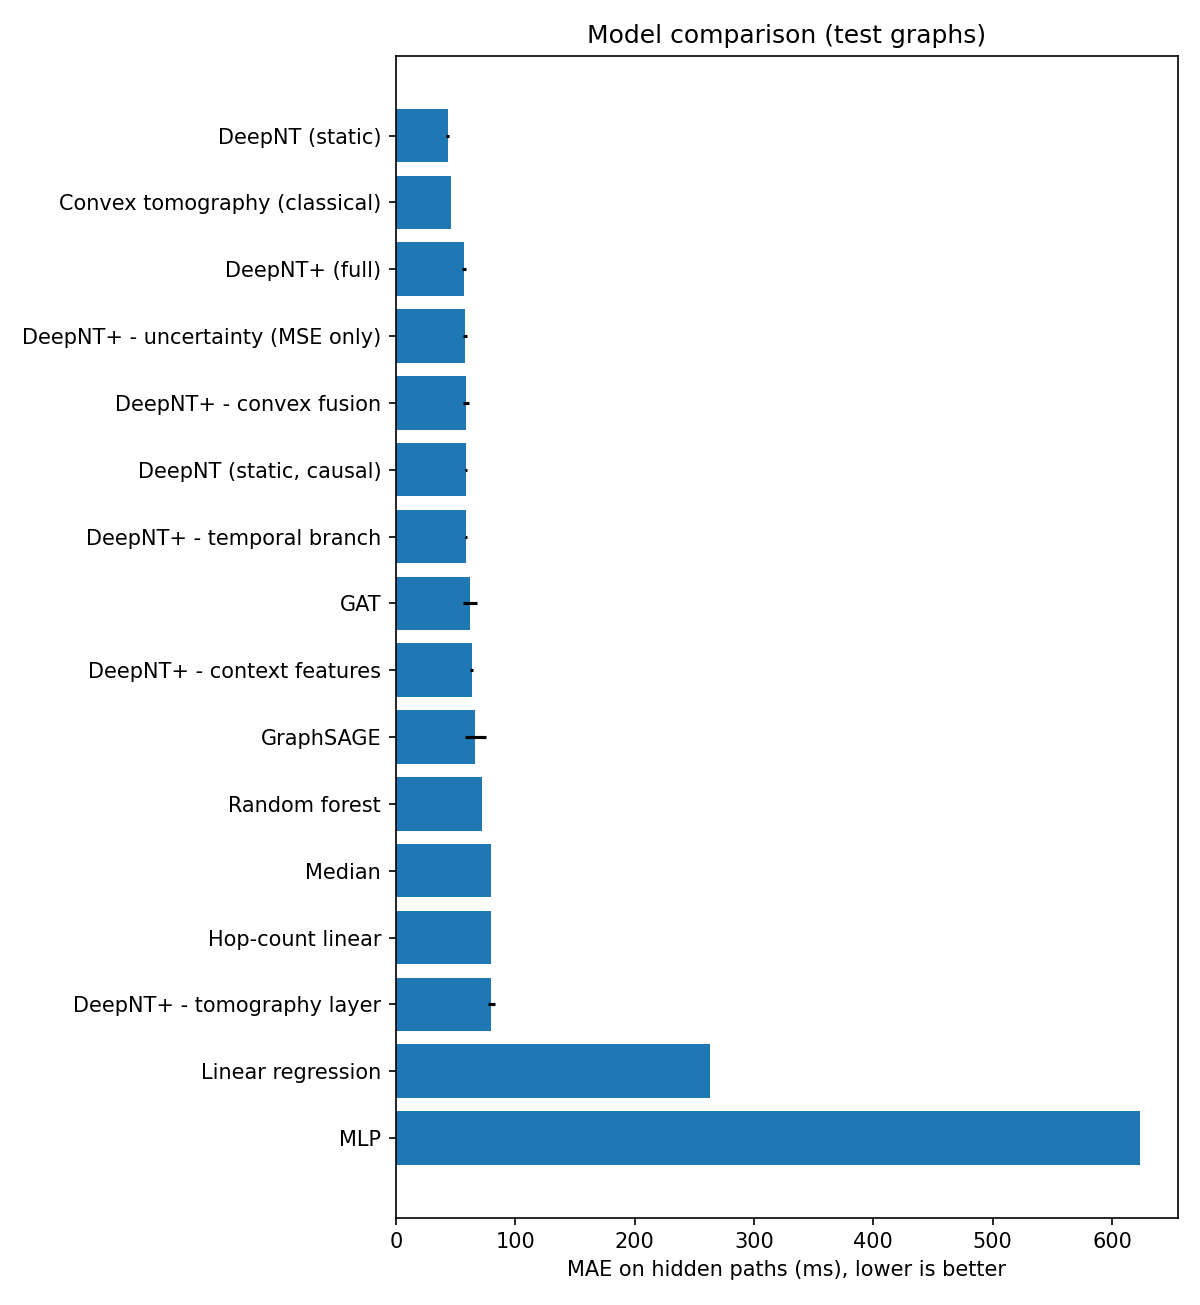

active_learning.png


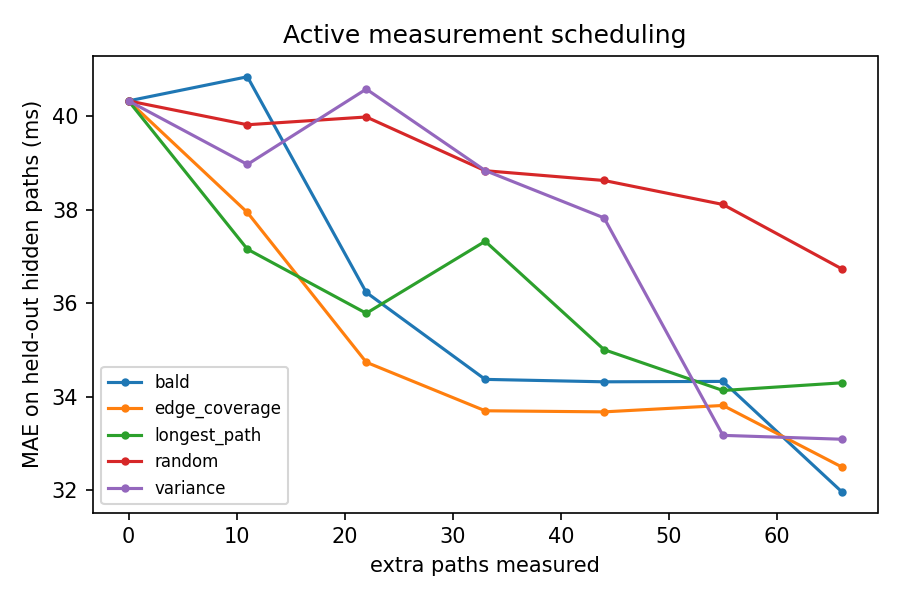

In [9]:
from IPython.display import Image, display
for f in report.make_all(OUT_DIR):
    print(f.name)
    display(Image(filename=str(f)))


## Cross-vantage-point test (optional)

Set `HOLDOUT_MONITOR` to one Ark monitor (for example `"dac-bd"`). Every graph dominated by that monitor becomes a test graph and the
model trains only on the other monitors. This is a much harder question than the standard split: does the model transfer to a vantage
point it has never seen? Expect worse numbers and read them as a robustness result.

In [10]:
HOLDOUT_MONITOR = None        # e.g. "dac-bd"
if HOLDOUT_MONITOR:
    hold_dir = OUT_DIR.parent / f"{RUN_NAME}_holdout_{HOLDOUT_MONITOR}"
    _, hold_summary = run_all(PROCESSED, hold_dir, seeds=SEEDS, epochs=EPOCHS, variants=["GraphSAGE", "DeepNT (static)"],
                              ablations=False, active_learning=False, fast=FAST, holdout_monitor=HOLDOUT_MONITOR)
    hc = [c for c in ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean"] if c in hold_summary.columns]
    print(f"test = graphs dominated by {HOLDOUT_MONITOR}; results saved to {hold_dir}")
    print(hold_summary[hold_summary.split == "test"][hc].sort_values("MAE_mean").round(3).to_string(index=False))
else:
    print("set HOLDOUT_MONITOR to run the cross-vantage-point test")


set HOLDOUT_MONITOR to run the cross-vantage-point test


## How to read these results

- **Claims you can make:** the model predicts the RTT of hidden paths on unseen graphs; how far it beats the baselines; how well its uncertainty is
  calibrated; which components matter (only where the ablation gap exceeds the seed spread); whether uncertainty-driven measurement scheduling beats random.
- **Claims you cannot make yet:** anything about packet loss (no labels), long-horizon temporal dynamics (the measurements cover about two days and
  almost no path repeats), or comparisons with RIPE Atlas or EvolveGCN (not in this dataset / not implemented).
- **Where the temporal branch can help:** only if RTT drifts within the two days. If `DeepNT+ (full)` does not beat `DeepNT (static, causal)` by more
  than the seed spread, report that honestly: it is a legitimate finding about this data, not a bug.
